This is the Titanic ML project from Kaggle where we are going to predict whether passengers survived or did not survive on the Titanic based on some info about them. We are given a train.csv and test.csv. It is a binary classification problem because they either survived or did not survive and only those 2 options

In [ ]:
#imports 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


Reading in the data and looking at structure of the data

In [ ]:
data = pd.read_csv('C:/Users/stevi/Downloads/train.csv')
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,433.000000,433.000000,433.000000,364.000000,433.000000,433.000000,433.000000
mean,439.757506,0.526559,1.824480,30.662308,0.965358,0.711316,56.902954
std,253.159139,0.499872,0.874882,16.616720,1.404754,1.014837,62.368464
min,2.000000,0.000000,1.000000,0.750000,0.000000,0.000000,15.045800
25%,225.000000,0.000000,1.000000,19.000000,0.000000,0.000000,26.000000
50%,447.000000,1.000000,2.000000,31.000000,1.000000,0.000000,31.275000
75%,646.000000,1.000000,3.000000,42.000000,1.000000,1.000000,69.550000
max,890.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [19]:
#Splitting into features and label
X = data.drop(labels=['PassengerId','Survived','Name','Ticket'], axis=1)
y = data['Survived']

Now lets find patterns and correlation throughout pre processing

In [20]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Sex       891 non-null    str    
 2   Age       714 non-null    float64
 3   SibSp     891 non-null    int64  
 4   Parch     891 non-null    int64  
 5   Fare      891 non-null    float64
 6   Cabin     204 non-null    str    
 7   Embarked  889 non-null    str    
dtypes: float64(2), int64(3), str(3)
memory usage: 55.8 KB


Going to drop Cabin because too many nulls, encoding sex and embarked, replacing na values in numeric with median, replacing str na with most frequent

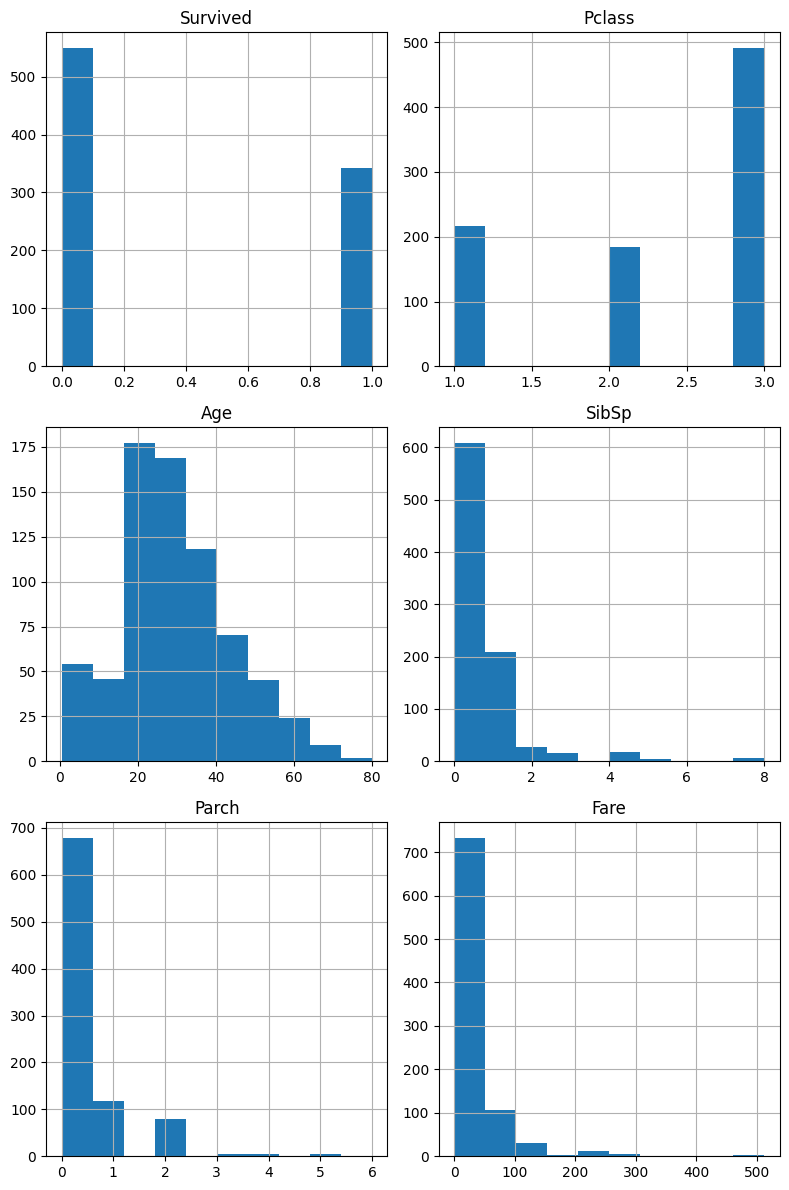

In [24]:
data.drop('PassengerId',axis=1).hist(bins=10, figsize=(8,12))
plt.tight_layout()
plt.show()


In [29]:
#checking to see which columns have the most correlation to Survived
corr_matrix = data.corr(numeric_only=True)
corr_matrix['Survived'].sort_values(ascending=False)

Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.077221
Pclass        -0.338481
Name: Survived, dtype: float64

[]

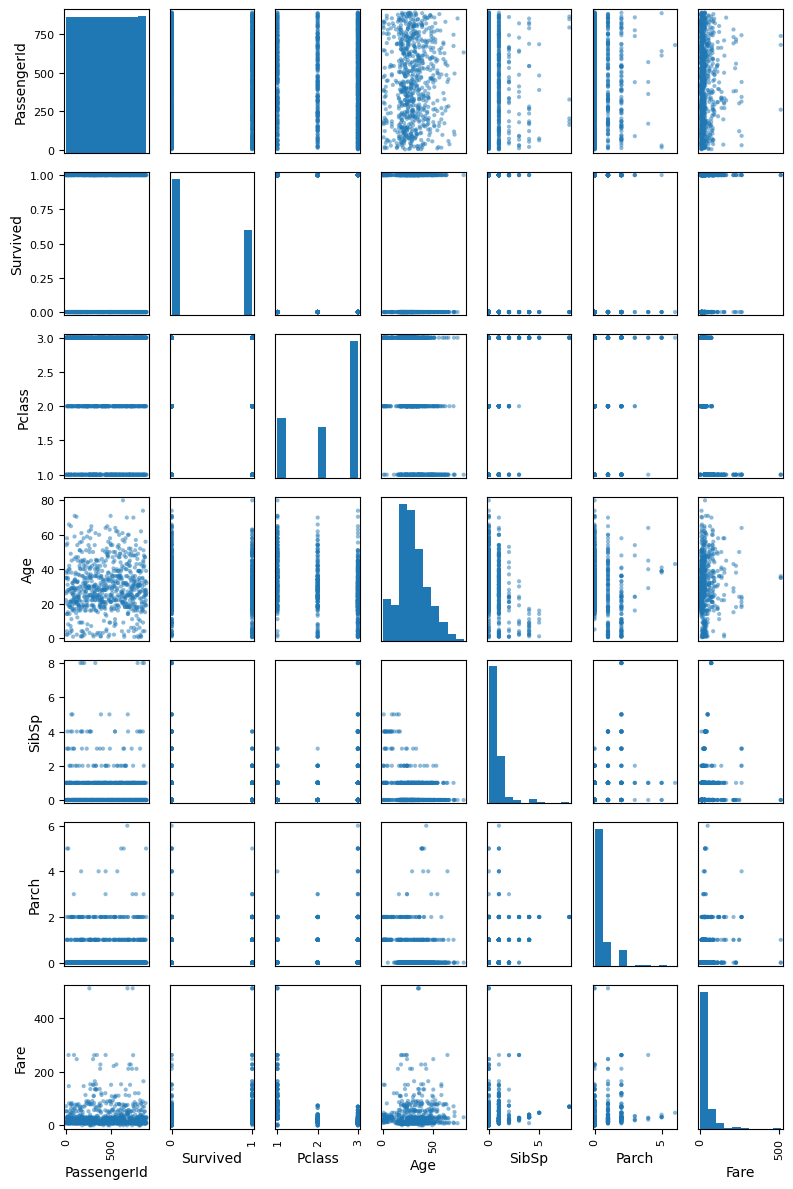

In [32]:
from pandas.plotting import scatter_matrix
scatter_matrix(data, figsize=(8,12))
plt.tight_layout()
plt.plot()

After looking at the correlations, I found as survival increased the Fare(price of ticket) increased, and the SibSp(number of siblings/parents) decreased along with age and the class by 0.33(suprising)

Now creating the pipelines to transform the data

In [ ]:
cat_transformer = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('encode', OneHotEncoder())
])#replaces na with most common and encodes to numerical vals
numeric_transformer = Pipeline([
    ('impute', SimpleImputer('median')),
    ('scale', StandardScaler())
])#replaces na with median from training and scales to a z score based on the mew and sigma of training data


